# کارخانهٔ دادهٔ ۳۱۱ نیویورک: مرحلهٔ ۱

در این نوتبوک کارخانه‌ای را اجرا و بررسی می‌کنم که از API زندهٔ شکایت‌های ۳۱۱ نیویورک، یک dataset تمیز، مستند و تکرارپذیر می‌سازد. سؤال تیم تحلیل این است: **«در هر محله، شهرداری برای هر نوع شکایت چقدر طول می‌کشد تا پرونده را ببندد، و این عدد بهتر می‌شود یا بدتر؟»** کار من جواب دادن به این سؤال نیست. کار من ساختن داده‌ای است که بشود با خیال راحت به آن جواب داد.

همهٔ منطق در پوشهٔ `src/data_factory/` است. اینجا فقط آن را صدا می‌زنم و نتیجه‌ها را توضیح می‌دهم. دلیل هر تصمیم در `report.md` و با جزئیات بیشتر در `docs/decisions.md` آمده است.

**نحوهٔ اجرا:** از ریشهٔ پروژه، با `Kernel → Restart & Run All`. اگر دادهٔ خام از قبل دانلود نشده باشد، اجرای اول حدود ۲۰ درخواست به API می‌فرستد. زمان این دانلود اولیه جزو سقف ۱۵ دقیقه نیست.

**بخش‌ها:**
1. آماده‌سازی
2. اجرای کامل کارخانه
3. manifest اجرا
4. قطعی بودن: اجرای دوم، همان hashها
5. تست‌ها
6. سقف حافظه
7. قرنطینه در عمل
8. انتخاب دامنهٔ داده
9. منبع دوم: جمعیت و borough
10. تکراری‌ها
11. گزارش کیفیت داده
12. خروجی اصلی: جدول‌های wide
13. تحلیل اکتشافی (EDA)
14. سه یافتهٔ غیربدیهی

## ۱. آماده‌سازی

کتابخانه‌ها را import می‌کنم، seed تصادفی را **یک جا** ثابت می‌کنم، و تنظیمات را از `factory.toml` می‌خوانم. همهٔ مسیرها نسبی‌اند و نسبت به فایل تنظیمات حل می‌شوند، پس نوتبوک روی هر ماشینی که پروژه را از ریشه اجرا کند کار می‌کند.

In [1]:
import json
import logging
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_factory import analysis, pipeline
from data_factory.config import load_config
from data_factory.publish import CASES_FILE, QUALITY_FILE, summary_file
from data_factory.references import load_borough_reference

SEED = 42
np.random.seed(SEED)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
logging.basicConfig(level=logging.INFO, stream=sys.stdout, force=True,
                    format="%(levelname)-7s %(name)s: %(message)s")

CONFIG = load_config("factory.toml")
CURATED = Path("data/curated")
scope = CONFIG.scope
print("agencies:        ", scope.agencies)
print("complaint types: ", scope.complaint_types)
print("window:          ", scope.window_start.date(), "to", scope.window_end.date(), "(end excluded)")
print("as_of cut-off:   ", CONFIG.as_of.date())

agencies:         ('HPD',)
complaint types:  ('HEAT/HOT WATER', 'UNSANITARY CONDITION', 'PLUMBING', 'PAINT/PLASTER', 'DOOR/WINDOW', 'WATER LEAK')
window:           2024-01-01 to 2025-07-01 (end excluded)
as_of cut-off:    2026-10-01


## ۲. اجرای کامل کارخانه

کل کارخانه را با یک فرمان اجرا می‌کنم: `fetch → validate → clean → enrich → publish`. این دقیقاً همان کاری است که دستور `data-factory run` در خط فرمان انجام می‌دهد.

- **fetch:** دریافت صفحه‌به‌صفحه از API و دو منبع مرجع. اگر snapshot از قبل کامل باشد، دوباره دانلود نمی‌کند و فقط schema را بررسی می‌کند.
- **validate:** بازرسی هر رکورد با قرارداد. رکورد معیوب حذف نمی‌شود، به قرنطینه می‌رود.
- **clean:** تبدیل نوع‌ها، ستون‌های مشتق، برچسب‌ها و تکراری‌ها.
- **enrich:** اتصال جمعیت و بررسی borough.
- **publish:** سه خروجی نهایی در `data/curated/`.

In [2]:
started = time.perf_counter()
pipeline.run(pipeline.RunContext(config=CONFIG), list(pipeline.STAGE_NAMES))
print(f"\nwhole factory: {time.perf_counter() - started:.0f} seconds")

INFO    data_factory.pipeline: stage fetch: start
INFO    data_factory.sources: source schema ok: 15 expected columns present with expected types
INFO    data_factory.ingest: snapshot snapshot-2c0ffe825cb1 is complete: nothing to download
INFO    data_factory.pipeline: fetch: 0 new pages, 0 new records, segment snapshot-2c0ffe825cb1
INFO    data_factory.pipeline: fetch: HTTP calls 1, attempts 1
INFO    data_factory.pipeline: stage fetch: done
INFO    data_factory.pipeline: stage validate: start
INFO    data_factory.validation: validate: 927361 raw, 927361 valid, 0 quarantined (0.0000%)
INFO    data_factory.pipeline: stage validate: done
INFO    data_factory.pipeline: stage clean: start
INFO    data_factory.cleaning: clean: 927361 rows, 5091 open, 35573 duplicate rows in 32543 groups
INFO    data_factory.pipeline: stage clean: done
INFO    data_factory.pipeline: stage enrich: start
INFO    data_factory.enrichment: enrich: 927361 rows before join, 927361 after; population {'matched': 927

## ۳. manifest اجرا

manifest می‌گوید این اجرا دقیقاً چه کرده: بازهٔ دریافت‌شده، تعداد رکورد خام و عبورکرده، قرنطینه به تفکیک دلیل، زمان شروع و پایان، نسخهٔ کد، و hash هر فایل خروجی. خود manifest زمان اجرا را دارد، پس جزو فایل‌هایی نیست که hash می‌شوند.

In [3]:
manifest = json.loads((CURATED / "run_manifest.json").read_text(encoding="utf-8"))
counts = manifest["counts"]
print("window:              ", manifest["scope"]["window_start"], "to", manifest["scope"]["window_end_exclusive"])
print("raw records:         ", counts["raw_records"])
print("passed the contract: ", counts["passed_contract"])
print("quarantined:         ", counts["quarantined"], f"(ratio {counts['quarantine_ratio']})")
print("quarantine by reason:", {k: v for k, v in counts["quarantine_by_reason"].items()})
print("started / finished:  ", manifest["run"]["started_at_utc"], "/", manifest["run"]["finished_at_utc"])
print("seconds per stage:   ", manifest["run"]["stage_seconds"])
print("code version:        ", manifest["code"])
print("requests this run:   ", manifest["requests"]["this_run"])
print("requests, full download from an empty folder:", manifest["requests"]["full_download"])
pd.DataFrame(manifest["outputs"]).T

window:               2024-01-01T00:00:00 to 2025-07-01T00:00:00
raw records:          927361
passed the contract:  927361
quarantined:          0 (ratio 0.0)
quarantine by reason: {'BOROUGH_INVALID': 0, 'CLOSED_BEFORE_CREATED': 0, 'CLOSED_IN_FUTURE': 0, 'INVALID_KEY': 0, 'MISSING_REQUIRED': 0, 'OUT_OF_SCOPE': 0, 'OUT_OF_WINDOW': 0, 'UNPARSEABLE_DATE': 0, 'ZIP_MALFORMED': 0}
started / finished:   2026-10-24T20:36:31 / 2026-10-24T20:39:36
seconds per stage:    {'clean': 74.9, 'enrich': 18.0, 'fetch': 1.7, 'publish': 48.6, 'validate': 42.4}
code version:         {'git_commit': '6666e631d1c529d9a782cfe665090503ede1758c', 'git_dirty': True, 'package': '0.1.0'}
requests this run:    {'attempts': 1, 'calls': 1, 'retries': 0}
requests, full download from an empty folder: {'pages': 19, 'references': 2, 'schema_check': 1, 'total': 22}


,bytes,rows,sha256
curated/cases.csv,249969059,927361,b551d4dfe27521eb61bedae4492b0839dd8bf82411a895...
curated/quality_report.csv,1920,28,4bcb6bd266fc1bd221590a3b3dcbc4af82a97eccd27d3e...
curated/summary_borough_cases.csv,3242,30,daf90d317c308e87cb2a7906f62d8264a1e8cb0e0e6cdd...
curated/summary_borough_median_days.csv,3670,30,6f90564a234f2761cb9c7d9bd813d8bac2ae77a8c8b700...
curated/summary_borough_rate.csv,4169,30,7f9d00f53f1a74461a8c92e756fcbeeb3758b8c7bae7fc...
curated/summary_modzcta_cases.csv,72708,1054,10650eb140bf475e43cda79a6123cff634e6b20346fe3a...
curated/summary_modzcta_median_days.csv,74945,1054,e1ab1a8aadbaaed7b5cd323c1fe3b64ebb14f4224e6553...
curated/summary_modzcta_rate.csv,85039,1054,b2ad8ce7869eefbf5b6effebb9d6ec1d458688b5b4c211...
quarantine/quarantine.csv,216,0,b402508a3e99486bb7beac5909b4faf4216708cf9fbc8c...


**بودجهٔ درخواست:** دانلود کامل از پوشهٔ خالی به ۱ درخواست برای بررسی schema، یک درخواست برای هر صفحهٔ ۵۰ هزار رکوردی، و ۲ درخواست برای منابع مرجع نیاز دارد. از این کمتر نمی‌شود: تعداد صفحه‌ها برابر سقف «تعداد رکورد ÷ اندازهٔ صفحه» است، و صفحهٔ کوتاه آخر نشان می‌دهد داده تمام شده، پس درخواست خالی اضافه فرستاده نمی‌شود. تنها راه کمتر کردن، صفحهٔ بزرگ‌تر است، که هر درخواست را سنگین‌تر و احتمال timeout را بیشتر می‌کند.

## ۴. قطعی بودن: اجرای دوم باید همان hashها را بدهد

ایستگاه‌های پردازش را یک بار دیگر اجرا می‌کنم. ورودی‌ها یکی‌اند (همان snapshot، همان تنظیمات، همان commit کد)، پس hash همهٔ خروجی‌ها باید یکی باشد. manifest جدید خودش با اجرای قبلی مقایسه می‌کند و نتیجه را ثبت می‌کند.

برای اینکه دو اجرای مستقل از یک منبع زنده نتیجهٔ یکسان بدهند، سه کار کرده‌ام: snapshot خام بعد از کامل شدن دیگر تغییر نمی‌کند؛ پرونده‌ای که بعد از تاریخ برش `as_of` بسته شده، «هنوز باز» حساب می‌شود؛ و همهٔ فایل‌ها با ترتیب ثابت، فرمت ثابت اعداد و تاریخ، و پایان خط `\n` نوشته می‌شوند.

In [4]:
pipeline.run(pipeline.RunContext(config=CONFIG), ["validate", "clean", "enrich", "publish"])
second = json.loads((CURATED / "run_manifest.json").read_text(encoding="utf-8"))
second["determinism"]

INFO    data_factory.pipeline: stage validate: start
INFO    data_factory.validation: validate: 927361 raw, 927361 valid, 0 quarantined (0.0000%)
INFO    data_factory.pipeline: stage validate: done
INFO    data_factory.pipeline: stage clean: start
INFO    data_factory.cleaning: clean: 927361 rows, 5091 open, 35573 duplicate rows in 32543 groups
INFO    data_factory.pipeline: stage clean: done
INFO    data_factory.pipeline: stage enrich: start
INFO    data_factory.enrichment: enrich: 927361 rows before join, 927361 after; population {'matched': 927233, 'zip_missing': 120, 'zip_not_in_reference': 8}; borough check {'consistent': 927234, 'not_checkable': 127}
INFO    data_factory.pipeline: stage enrich: done
INFO    data_factory.pipeline: stage publish: start
INFO    data_factory.publish: publish: 927361 cases; summaries {'summary_borough_median_days.csv': 30, 'summary_borough_cases.csv': 30, 'summary_borough_rate.csv': 30, 'summary_modzcta_median_days.csv': 1054, 'summary_modzcta_cases.c

{'changed': [],
 'identical_outputs': True,
 'previous_run': '2026-10-24T20:36:31',
 'same_inputs': True}

## ۵. تست‌ها

همهٔ تست‌ها با `unittest` و با یک فرمان (Test Discovery) اجرا می‌شوند، و هیچ‌کدام به اینترنت وصل نمی‌شوند. چند تست مهم:

- **خطا و پاسخ ناقص API:** تلاش دوباره برای 429 و 5xx، توقف برای 400، و رد پاسخ ۲۰۰ ای که HTML است (`tests/test_http_client.py`).
- **ازسرگیری:** قطع در صفحهٔ ۳ و ادامه دقیقاً از آخرین کلید، بدون تکرار و بدون جاافتادگی (`test_interrupted_run_resumes_after_last_complete_page`).
- **قرنطینه:** رکورد معیوب قرنطینه می‌شود و رکورد سالم نه (`tests/test_contract.py`).
- **حالت‌های مرزی:** مرز بازهٔ زمانی، بستن دقیقاً در لحظهٔ `as_of`، تکراری‌هایی که در دو chunk مختلف افتاده‌اند، و پروندهٔ باز در محاسبهٔ میانه.
- **کل کارخانه دو بار، با hash یکسان** (`test_second_run_has_identical_output_hashes`).

In [5]:
result = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
                        capture_output=True, text=True)
print("\n".join(result.stderr.strip().splitlines()[-3:]))

Ran 156 tests in 6.516s

OK


## ۶. سقف حافظه

شرط مسئله این است که هیچ‌وقت کل دادهٔ خام هم‌زمان در حافظه نباشد. همهٔ ایستگاه‌ها دادهٔ خام را صفحه‌به‌صفحه می‌خوانند. برای نشان دادنش، با `tracemalloc` دو اندازه می‌گیرم: بیشترین حافظه هنگام خواندن **فقط یک صفحه**، و هنگام خواندن **همهٔ صفحه‌ها** پشت سر هم. اگر داده‌ها در حافظه جمع می‌شدند، عدد دوم با تعداد صفحه‌ها بزرگ می‌شد.

In [6]:
segments = [segment.store for segment in pipeline.chain(CONFIG).segments()]
memory = analysis.raw_memory_profile(segments)
memory

{'pages': 19,
 'records': 927361,
 'raw_mb_on_disk': 464.6,
 'peak_mb_reading_one_page': 104.2,
 'peak_mb_reading_all_pages': 208.5,
 'all_pages_peak_vs_one_page': 2.0,
 'estimated_mb_if_all_pages_were_held': 1980.1}

اوج حافظه هنگام خواندن **یک** صفحه حدود ۱۰۴ مگابایت است، و هنگام خواندن **هر ۱۹** صفحه حدود ۲۰۸ مگابایت: فقط دو برابر، نه نوزده برابر. دو برابر است چون وقتی صفحهٔ بعد خوانده می‌شود، صفحهٔ قبلی هنوز در حافظه است. اگر همهٔ صفحه‌ها هم‌زمان در حافظه بودند، حدود ۲ گیگابایت لازم می‌شد. یعنی حافظه به اندازهٔ صفحه بستگی دارد، نه به تعداد صفحه‌ها، و اگر داده دو برابر شود، اوج حافظه تقریباً همین می‌ماند. ایستگاه validate هم دقیقاً با همین خواندن صفحه‌به‌صفحه کار می‌کند.

## ۷. قرنطینه در عمل

در اجرای واقعی هیچ رکوردی قرنطینه نشد. دلیلش این است که فیلتر درخواست API همان دامنه و بازه را اعمال می‌کند، و فیلدهای اصلی را خود سیستم ۳۱۱ پر می‌کند. پس برای اینکه نشان دهم قرنطینه واقعاً کار می‌کند، یک **کپی** از صفحهٔ اول دادهٔ واقعی را عمداً خراب می‌کنم. دادهٔ واقعی دست نمی‌خورد.

- **خرابی کوچک:** ۱۰ رکورد با تاریخ بستن قبل از تاریخ ثبت، و ۱۰ رکورد با فرمت تاریخ دیگر. باید دقیقاً همین ۲۰ رکورد، با دلیل درست، قرنطینه شوند.
- **خرابی گسترده:** فرمت تاریخ **همهٔ** رکوردها عوض می‌شود، مثل وقتی که منبع رفتارش را تغییر دهد. اجرا باید متوقف شود و فایل رکوردهای سالم منتشر نشود.

In [7]:
demo = analysis.quarantine_demo(segments[0], CONFIG.scope, CONFIG.zip.placeholders, CONFIG.max_quarantine_ratio)
pd.Series(demo["small_corruption"]), pd.Series(demo["wide_corruption"])

INFO    data_factory.validation: validate: 50000 raw, 49980 valid, 20 quarantined (0.0400%)
INFO    data_factory.validation:   UNPARSEABLE_DATE         10
INFO    data_factory.validation:   CLOSED_BEFORE_CREATED    10
INFO    data_factory.validation: validate: 50000 raw, 0 valid, 50000 quarantined (100.0000%)
INFO    data_factory.validation:   UNPARSEABLE_DATE         50000


(records_in_copy                                                             50000
 quarantined                                                                    20
 exactly_the_broken_ones                                                      True
 closed_before_created_caught                                                 True
 unparseable_date_caught                                                      True
 reasons                         {'UNPARSEABLE_DATE': 10, 'CLOSED_BEFORE_CREATE...
 dtype: object,
 run_stopped                                                          True
 message                 100.0000% of records were quarantined, above t...
 valid_file_published                                                False
 dtype: object)

در خرابی کوچک، دقیقاً همان ۲۰ رکورد خراب‌شده قرنطینه شدند، هر کدام با دلیل درست، و بقیهٔ صفحه عبور کرد. در خرابی گسترده، سهم قرنطینه از آستانهٔ ۱٪ گذشت، اجرا متوقف شد، و فایل رکوردهای سالم منتشر نشد. فایل قرنطینه همیشه نوشته می‌شود، چون شاهد است.

آستانهٔ ۱٪ را برای **خرابی ساختاری** گذاشته‌ام، نه خطای تصادفی، چون نرخ پایهٔ قرنطینه صفر است. کوچک‌ترین خرابی ساختاری که می‌خواهم حتماً بگیرم، خراب شدن یک هفته داده است (حدود ۱.۳٪ کل داده).

## ۸. انتخاب دامنهٔ داده

API در بازهٔ ۱۸ ماهه بیش از ۵ میلیون رکورد دارد، پس باید دامنه را محدود می‌کردم. پنج نامزد را با معیارهای یکسان سنجیدم. این جدول را اسکریپت `explore/03_measure_candidates.py` ساخته (اجرا: 2026-10-24) و در `docs/evidence/` ذخیره شده تا عددهای گزارش قابل ردیابی باشند.

In [8]:
pd.read_csv("docs/evidence/scope_candidates.csv").set_index("scope")

,total,n_types,top3_types_share_pct,pct_open,median_hours,p90_hours,pct_under_1h,pct_zip_missing,pct_zip_bad_pattern,n_not_closed_with_date
scope,,,,,,,,,,
HPD_all,1115080,13.0,63.0,0.49,80.8,908.9,0.4,0.01,0.00,12.0
HPD_top6,927361,6.0,75.7,0.55,64.4,742.1,0.4,0.01,0.00,7.0
DSNY_all,467410,30.0,46.5,0.54,27.0,251.9,2.2,1.83,0.95,4.0
NYPD_noise,1020116,6.0,91.7,0.00,0.8,6.9,59.3,0.01,0.02,125.0
noise_all_agencies,1142099,8.0,81.9,0.45,0.9,39.6,52.4,0.01,0.02,126.0
DOT_all,315424,33.0,NaN,1.92,NaN,NaN,NaN,NaN,NaN,NaN
ALL_AGENCIES,5215586,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**HPD با شش نوع شکایت** را انتخاب کردم. شکایت‌های سروصدا را کنار گذاشتم، چون بیشتر از نیمشان زیر یک ساعت بسته می‌شوند و «بستن پرونده» آنجا یعنی رسیدن مأمور، نه حل شدن مشکل. ترکیب چند آژانس را هم کنار گذاشتم، چون «بستن» در هر آژانس معنای خودش را دارد: با اضافه شدن DEP به سروصدا، صدک ۹۰ از ۶.۹ به ۳۹.۶ ساعت پرید. DSNY سی نوع شکایت دارد و جدول wide را شلوغ می‌کند. DOT هم فقط حدود ۵٪ بالای حداقل ۳۰۰ هزار رکورد است. معیار انتخاب در تنظیمات است، نه در کد، و در manifest ثبت می‌شود.

## ۹. منبع دوم: جمعیت و borough

برای اینکه «۱۲ شکایت» در یک منطقهٔ کوچک با «۱۲ شکایت» در منطقه‌ای ده برابر پرجمعیت‌تر یکی دیده نشود، نرخ به ازای جمعیت لازم است. دو منبع مرجع گرفتم:

- **MODZCTA** از NYC Open Data: جمعیت هر منطقهٔ کد پستی، و فهرست کدهای پستی هر منطقه.
- **فایل رابطهٔ ZCTA و county** از سرشماری ۲۰۲۰: هر کد پستی به کدام borough می‌رسد. فقط برای **کنترل** ستون borough دادهٔ ۳۱۱.

اتصال با lookup است، یعنی هر کلید فقط یک مقدار دارد، پس تعداد سطرها نمی‌تواند عوض شود. با این حال، تعداد قبل و بعد را می‌شمارم.

In [9]:
enrich = counts["enrich"]
print("rows before / after the join:", enrich["rows_before_join"], "/", enrich["rows_after_join"])
print("zip alias 11249 -> 11211 applied to:", enrich["alias_applied"], "rows")
print("population status:", enrich["population_status"])
print("zips with no population area:", enrich["unmatched_zips"])
print("borough check:", enrich["borough_check"])
print("reference files:", json.dumps(enrich["reference"]["files"], indent=1))

rows before / after the join: 927361 / 927361
zip alias 11249 -> 11211 applied to: 1311 rows
population status: {'matched': 927233, 'zip_missing': 120, 'zip_not_in_reference': 8}
zips with no population area: {'10041': 2, '10105': 1, '10121': 1, '10123': 1, '10158': 1, '10803': 1, '11241': 1}
borough check: {'consistent': 927234, 'not_checkable': 127}
reference files: {
 "population": {
  "retrieved_at_utc": "2026-10-24T18:28:32",
  "url": "https://data.cityofnewyork.us/resource/pri4-ifjk.json"
 },
 "zcta_county": {
  "retrieved_at_utc": "2026-10-24T18:28:34",
  "url": "https://www2.census.gov/geo/docs/maps-data/data/rel2020/zcta520/tab20_zcta520_county20_natl.txt"
 }
}


- **کد پستی 11249** در ژوئیهٔ ۲۰۱۱ از دل 11211 جدا شد، ولی MODZCTA بر اساس نقشهٔ ۲۰۱۰ است. پس منطقهٔ 11211 در آن، جمعیت محدودهٔ امروزِ 11249 را هم دارد. این کد را از طریق یک جدول alias در تنظیمات به 11211 وصل کردم. صورت و مخرج کسر از یک محدوده‌اند.
- **رکوردهایی که جمعیت پیدا نکردند** حذف نمی‌شوند. یا کد پستی ندارند (یا کدشان ساختگی بوده، مثل `12345`)، یا کدشان یک کد تجاری بدون ساکن است، مثل 10041. این رکوردها فقط از مخرج نرخ بیرون می‌مانند.

حالا borough دادهٔ ۳۱۱ را با دو قاعده با فایل سرشماری مقایسه می‌کنم:

In [10]:
cases = analysis.load_cases(CURATED / CASES_FILE)
files = pipeline.references(CONFIG)
boroughs = load_borough_reference(files.zcta_county, CONFIG.references.county_boroughs)
rules = analysis.borough_rule_comparison(cases, boroughs)
print("rows checked:", rules["rows_checked"])
print("disagreements, 'borough with the largest land area' rule:", rules["largest_area_rule_disagreements"])
print("disagreements, 'one of the boroughs this zip touches' rule:", rules["legal_rule_disagreements"])
rules["disagreements_by_zip"]

rows checked: 927234
disagreements, 'borough with the largest land area' rule: 2005
disagreements, 'one of the boroughs this zip touches' rule: 0


,incident_zip,borough,rows,largest_area_rule_says,zip_is_split
0,10463,MANHATTAN,1955,BRONX,True
2,11001,QUEENS,43,OUTSIDE_NYC,True
3,11040,QUEENS,6,OUTSIDE_NYC,True
1,10803,BRONX,1,OUTSIDE_NYC,True


قاعدهٔ «borough با بیشترین مساحت» صدها اختلاف نشان می‌دهد، ولی **همهٔ آن‌ها روی کدهای پستی دوتکه‌اند**. مثلاً کد 10463 بیشترش در برانکس است، ولی محلهٔ Marble Hill آن از نظر قانونی جزو منهتن است، و ۳۱۱ آن را درست منهتن ثبت کرده. با قاعدهٔ «borough ۳۱۱ جزو boroughهایی است که این کد پستی به آن می‌رسد»، اختلاف **صفر** است. پس ستون borough دادهٔ ۳۱۱ از نگاشت کد پستی دقیق‌تر است، و من همان را به‌عنوان borough نهایی نگه داشتم، چون خدمات را ادارهٔ مسئولِ **قانونی** هر محدوده می‌دهد.

## ۱۰. تکراری‌ها

در این داده «تکراری» دو معنا دارد:

- **تکرار فنی:** همان `unique_key` دو بار، مثلاً به‌خاطر ازسرگیری. صفحه‌بندی کلیدی جلویش را می‌گیرد.
- **ثبت دوباره:** یک مشکل که دو بار با دو شناسهٔ متفاوت ثبت شده. تعریف من: **آدرس، نوع، موضوع، ثانیهٔ ثبت و ثانیهٔ بستن یکسان**. ثبت یک مشکل یکسان در همان ثانیه احتمالاً خطای سیستم است، و ثبت تکراری واقعی با هم هم بسته می‌شود.

سطرهای تکراری **پاک نمی‌شوند**. برچسب `is_duplicate` می‌گیرند، و هر گروه در شمارش و میانه فقط یک بار حساب می‌شود. دادهٔ عمومی ۳۱۱ هیچ مشخصاتی از ثبت‌کننده ندارد، پس «همان مکان» جای «همان فرد» را گرفته است.

قبل از انتخاب، چهار تعریف را روی همهٔ رکوردهای دو ماه سنجیدم:

In [11]:
display(pd.read_csv("docs/evidence/duplicate_definitions.csv").set_index("definition"))
clean_stats = counts["clean"]
print("whole dataset, final definition (with the same closing second):")
print("  rows marked duplicate:", clean_stats["duplicate_rows"],
      f"({100 * clean_stats['duplicate_rows'] / clean_stats['rows']:.2f}%)")
print("  duplicate groups:     ", clean_stats["duplicate_groups"])
print("  open cases:           ", clean_stats["open_cases"],
      f"({100 * clean_stats['open_cases'] / clean_stats['rows']:.3f}%)")

,keys,groups,rows_in_groups,rows_marked_duplicate,pct_of_sample
definition,,,,,
A,address + type + created second,10149,22835,12686,10.55
B,address + type + descriptor + created second,5007,10549,5542,4.61
C,building (bbl) + type + descriptor + created s...,4998,10530,5532,4.60
D,address + type + descriptor + same day,14190,38356,24166,20.09


whole dataset, final definition (with the same closing second):
  rows marked duplicate: 35573 (3.84%)
  duplicate groups:      32543
  open cases:            5091 (0.549%)


تعریف «همان روز» (D) یک‌پنجم داده را تکراری می‌داند، ولی بیشترش مستأجرهای مختلف یک ساختمان‌اند که یک قطعی را گزارش کرده‌اند. سطرهای هم‌ثانیه با **موضوع متفاوت** (تعریف A) هم تکراری نیستند: یک تماس است که چند مشکل را گزارش کرده. شرط «زمان بستن یکسان» گروه‌هایی را جدا می‌کند که HPD با آن‌ها مثل مشکل‌های جدا رفتار کرده. در کل داده، سهم تکراری‌ها کمی کمتر از عدد تعریف B در نمونهٔ دو ماهه است، همان‌طور که انتظار داشتم.

## ۱۱. گزارش کیفیت داده

این گزارش را کارخانه برای هر ستون **تولید می‌کند**: چند درصد خالی، چند مقدار یکتا، و چه دامنه‌ای. اولین نسخهٔ همین گزارش یک مشکل را نشان داد: ستون `community_board` مقدارهایی مثل `Unspecified QUEENS` داشت که در قواعد پاک‌سازی من نبود. آن‌ها را فقط با تغییر تنظیمات، بدون تغییر کد، به فهرست مقادیر «نامعلوم» اضافه کردم.

In [12]:
pd.read_csv(CURATED / QUALITY_FILE).set_index("column")

,rows,missing,missing_pct,distinct,min,max,most_common,most_common_count
column,,,,,,,,
unique_key,927361,0,0.0000,927361,59894394,67966648,59894394,1
created_at,927361,0,0.0000,648632,2024-01-01T00:01:14,2025-06-30T23:57:41,2024-01-15T08:17:16,15
closed_at,927361,5091,0.5490,278911,2024-01-01T09:58:04,2026-07-08T18:11:17,2025-02-24T21:21:20,197
is_open,927361,0,0.0000,2,False,True,False,922270
days_to_close,927361,5091,0.5490,483947,0.0,902.1268519,0,101
created_month,927361,0,0.0000,18,2024-01,2025-06,2025-01,98751
agency,927361,0,0.0000,1,HPD,HPD,HPD,927361
complaint_type,927361,0,0.0000,6,DOOR/WINDOW,WATER LEAK,HEAT/HOT WATER,427458
descriptor,927361,0,0.0000,28,APARTMENT ONLY,WINDOW/FRAME,ENTIRE BUILDING,279881


## ۱۲. خروجی اصلی: جدول‌های wide

برای هر سطح (borough و محله) سه جدول جدا ساختم: **میانهٔ روز تا بستن**، **تعداد مشکل‌ها**، و **نرخ به ازای هر ۱۰ هزار نفر**. هر جدول یک سطر برای هر «منطقه × نوع شکایت» و یک ستون برای هر ماه دارد، تا روند را بشود با یک نگاه دید.

دو قاعده:
- **پروندهٔ باز در میانه** حذف نمی‌شود. «کندتر از همهٔ پرونده‌های بسته» حساب می‌شود. حذفش میانه را به سمت پایین کج می‌کرد، چون دقیقاً کندترین پرونده‌ها حذف می‌شدند. اگر بیش از نیمِ یک خانه باز باشد، میانه نامعلوم است و خالی می‌ماند.
- **خانه‌ای با کمتر از ۲۰ پرونده** تعداد را نشان می‌دهد، ولی میانه و نرخ را نه، چون میانهٔ چند پرونده نویز است، نه روند.

In [13]:
borough_median = pd.read_csv(CURATED / summary_file("borough", "median_days"))
borough_median.head(12)

,borough,complaint_type,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
0,BRONX,DOOR/WINDOW,13.06,12.72,10.79,10.34,7.58,6.83,9.36,8.81,6.29,7.13,9.34,14.49,14.35,12.79,12.29,10.50,8.89,15.50
1,BRONX,HEAT/HOT WATER,1.23,0.98,1.02,1.01,0.95,1.06,1.33,1.60,1.41,1.27,1.38,1.86,1.49,1.50,1.17,1.32,1.27,1.26
2,BRONX,PAINT/PLASTER,9.04,10.01,7.61,7.09,5.39,4.93,7.06,7.24,5.71,5.17,6.87,8.18,8.70,7.13,6.96,7.13,6.34,7.96
3,BRONX,PLUMBING,9.59,8.18,7.52,8.32,6.12,5.39,7.93,8.04,6.26,5.65,7.87,8.62,11.02,9.21,7.10,8.22,6.89,6.25
4,BRONX,UNSANITARY CONDITION,11.92,10.36,8.68,7.76,6.18,5.85,8.23,8.22,6.24,6.44,9.37,13.91,14.38,12.30,10.07,9.54,8.04,12.33
5,BRONX,WATER LEAK,12.48,11.91,11.03,9.09,7.39,6.10,8.91,8.33,6.35,6.64,8.34,11.10,12.86,9.23,9.23,8.95,7.71,11.62
6,BROOKLYN,DOOR/WINDOW,14.41,14.94,12.83,11.29,8.12,11.76,12.56,11.35,7.25,6.87,12.91,15.59,16.73,15.84,12.74,8.81,6.40,8.03
7,BROOKLYN,HEAT/HOT WATER,1.67,1.25,1.33,1.21,1.16,1.52,1.77,2.84,1.70,1.59,2.03,2.47,1.93,1.84,1.33,1.35,1.19,1.28
8,BROOKLYN,PAINT/PLASTER,7.70,8.14,7.02,7.73,5.83,6.54,7.25,8.60,6.09,4.96,7.12,9.29,9.91,9.38,7.22,5.27,5.17,5.03
9,BROOKLYN,PLUMBING,7.64,9.40,8.29,8.38,6.27,7.45,9.04,9.57,5.96,6.06,9.52,12.32,10.10,9.22,7.31,7.13,5.72,5.78


In [14]:
neighbourhood_cases = pd.read_csv(CURATED / summary_file("modzcta", "cases"))
analysis.cell_size_distribution(neighbourhood_cases)

,min_cases,cells_kept,share_kept_pct
0,5,14439,82.6
1,10,11763,67.3
2,15,9790,56.0
3,20,8349,47.8
4,30,6627,37.9
5,50,4482,25.6


با حداقل ۲۰ پرونده، تقریباً نیمی از خانه‌های جدول محله میانه دارند. با ۱۰ پرونده، فاصلهٔ اطمینان میانه تقریباً کل داده را می‌پوشاند. با ۵۰، سه‌چهارم جدول خالی می‌شد. در سطح borough هیچ خانه‌ای پنهان نمی‌شود.

## ۱۳. تحلیل اکتشافی (EDA)

از اینجا به بعد روی جدول پرونده‌ها کار می‌کنم. سطرهای تکراری کنار گذاشته شده‌اند، پس هر سطر یک مشکل است.

### ۱۳.۱ آمار توصیفی مدت زمان بستن

In [15]:
analysis.duration_summary(cases)

,problems,open_pct,median,p25,p75,p90,mean,max
complaint_type,,,,,,,,
HEAT/HOT WATER,424451,1.03,1.57,0.90,2.41,3.29,1.79,552.2
PAINT/PLASTER,85307,0.15,7.03,3.05,18.47,48.70,18.90,897.0
PLUMBING,96484,0.2,7.46,2.90,21.17,57.06,21.24,902.1
UNSANITARY CONDITION,156249,0.12,9.26,4.28,23.03,58.09,22.48,810.3
WATER LEAK,63321,0.13,10.08,4.23,28.30,71.90,25.97,811.7
DOOR/WINDOW,65976,0.14,11.08,4.53,27.65,68.62,25.66,900.0


میانهٔ HEAT/HOT WATER حدود یک و نیم روز است (۱٫۵۷)، و میانهٔ بقیهٔ نوع‌ها بین ۷ تا ۱۱ روز. در همهٔ نوع‌های غیر گرمایشی، میانگین تقریباً **۲٫۵ تا ۳ برابر** میانه است (مثلاً PLUMBING: میانه ۷٫۴۶، میانگین ۲۱٫۲۴)، و بیشینه تا ۹۰۲ روز می‌رسد. یعنی توزیع به‌شدت به راست کشیده است، و برای همین در همهٔ جدول‌ها **میانه** را گزارش می‌کنم، نه میانگین.

### ۱۳.۲ نمودار ۱: توزیع مدت زمان بستن

**ادعا:** شکایت‌های گرمایش در دستهٔ کاملاً جدایی از بقیه قرار دارند، و توزیع همهٔ نوع‌ها کشیده و چندمرتبه‌ای است. محور افقی لگاریتمی است.

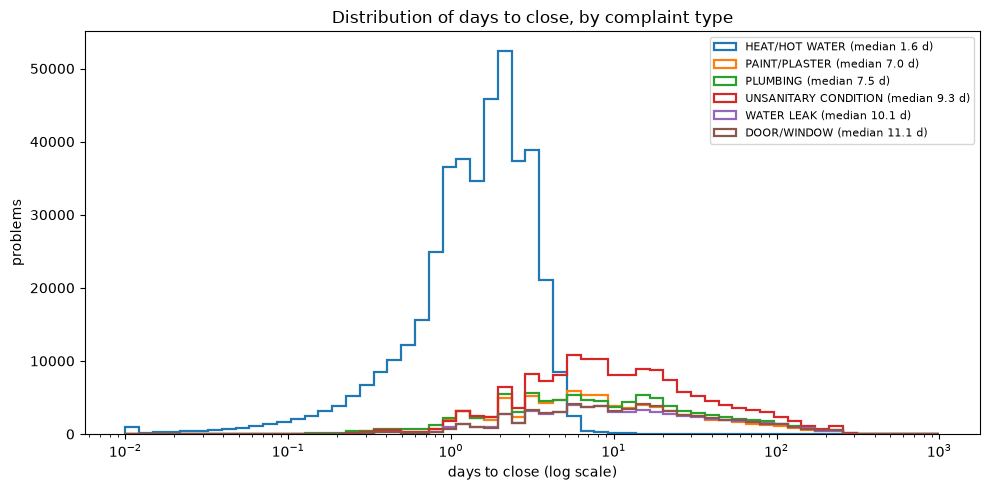

In [16]:
analysis.plot_duration_distribution(cases);

قلهٔ HEAT/HOT WATER حدود یک روز است، و قلهٔ بقیهٔ نوع‌ها حدود یک هفته، یعنی چند برابر کندتر. دنبالهٔ راست همهٔ نوع‌ها تا صدها روز می‌رسد. پس مقایسهٔ نوع‌ها با یک عدد میانگین گمراه‌کننده است، و تحلیل باید برای هر نوع جدا انجام شود.

### ۱۳.۳ Outlierها

In [17]:
analysis.outlier_summary(cases)

,fence_days,beyond_fence,beyond_fence_pct,over_one_year,zero_days
complaint_type,,,,,
DOOR/WINDOW,97.0,3893,5.91,14,8
HEAT/HOT WATER,6.9,793,0.19,11,43
PAINT/PLASTER,64.7,6016,7.06,25,11
PLUMBING,76.0,6683,6.94,21,13
UNSANITARY CONDITION,79.3,10260,6.57,24,15
WATER LEAK,100.5,3716,5.88,14,8


در نوع‌های غیر گرمایشی، حدود ۶ تا ۷٪ پرونده‌ها از حد «سه برابر دامنهٔ میان‌چارکی» بالاترند، و فقط ۱۰۹ مشکل بیش از یک سال باز مانده‌اند.

**تصمیم: outlierها را نگه می‌دارم.** پرونده‌ای که یک سال یا بیشتر باز مانده، خطای داده نیست. یک پروندهٔ واقعی و کند است، و دقیقاً همان چیزی است که تیم تحلیل باید ببیند. حذفش شهرداری را سریع‌تر از واقعیت نشان می‌داد. میانه در برابر این مقادیر مقاوم است، پس جدول‌های خلاصه از آن آسیب نمی‌بینند. پرونده‌های با مدت دقیقاً صفر هم حذف نمی‌شوند. برچسب `flag_zero_duration` دارند، تا هر تحلیلگری بتواند خودش تصمیم بگیرد.

### ۱۳.۴ نمودار ۲: فصل گرما و سرعت بقیهٔ شکایت‌ها

**ادعا:** در ماه‌هایی که شکایت‌های گرمایش زیاد است، **بقیهٔ** شکایت‌ها کندتر بسته می‌شوند. یعنی رابطهٔ دو متغیر عددی، «تعداد شکایت گرمایش در ماه» و «میانهٔ روز تا بستن بقیهٔ نوع‌ها»، مثبت است.

correlation between heat volume and the other types' median: {'pearson': 0.894, 'spearman': 0.851, 'months': 18}


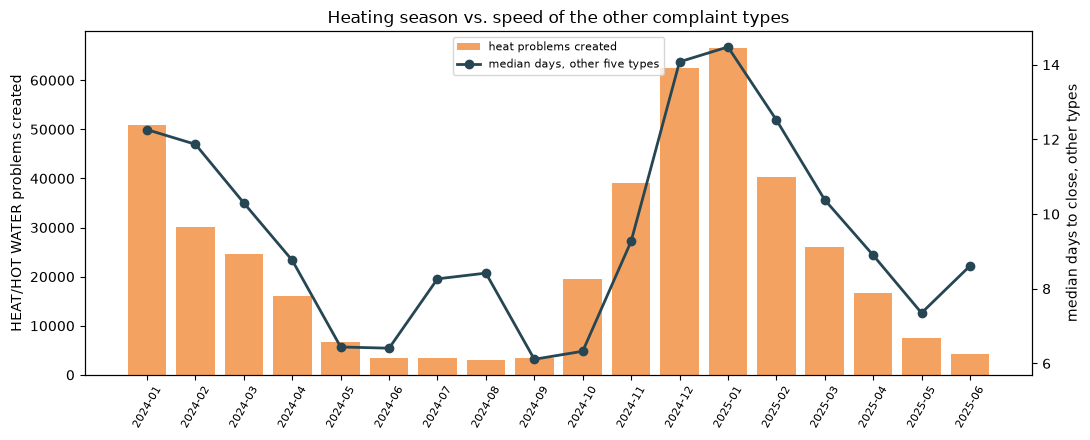

In [18]:
monthly, correlation = analysis.heat_versus_others(cases, "HEAT/HOT WATER")
print("correlation between heat volume and the other types' median:", correlation)
analysis.plot_heat_versus_others(monthly);

ستون‌ها (تعداد شکایت گرمایش) و خط (میانهٔ بقیهٔ نوع‌ها) با هم بالا و پایین می‌روند: هر دو در زمستان اوج می‌گیرند و در تابستان پایین می‌آیند. همبستگی در ۱۸ ماه **قوی و مثبت** است: پیرسون ۰٫۸۹ و اسپیرمن ۰٫۸۵. همبستگی علت را ثابت نمی‌کند، ولی توضیح ساده‌اش این است که در فصل گرما، ظرفیت بازرسی HPD صرف شکایت‌های فوری گرمایش می‌شود و بقیه عقب می‌افتند.

### ۱۳.۵ نمودار ۳: بهتر شده یا بدتر؟

اثر فصل آن‌قدر بزرگ است که مقایسهٔ دو ماه پشت سر هم گمراه‌کننده است. مقایسهٔ درست، **همان ماه‌ها در دو سال پشت سر هم** است: ژانویه تا ژوئن ۲۰۲۴ در برابر ژانویه تا ژوئن ۲۰۲۵. عددها از جدول خروجی `summary_borough_median_days.csv` می‌آیند.

**ادعا:** جواب سؤال «بهتر شده یا بدتر؟» در همهٔ شهر یکی نیست، و به borough بستگی دارد.

2024-01..2024-06  2025-01..2025-06  change_pct
borough       complaint_type                                                      
STATEN ISLAND UNSANITARY CONDITION             11.81              5.86       -50.4
              PAINT/PLASTER                     8.07              5.40       -33.1
              HEAT/HOT WATER                    2.17              1.52       -30.0
              PLUMBING                          8.77              6.76       -22.9
              WATER LEAK                        8.80              6.85       -22.2
BROOKLYN      WATER LEAK                       12.33             10.53       -14.6
              DOOR/WINDOW                      12.22             11.42        -6.5
              PLUMBING                          7.91              7.54        -4.7
              PAINT/PLASTER                     7.16              7.00        -2.2
              UNSANITARY CONDITION             10.94             10.71        -2.1
STATEN ISLAND DOOR/WINDOW                       9.60              9.57        -0.3
BRONX         PAINT/PLASTER                     7.34              7.37         0.4
              WATER LEAK                        9.67              9.93         2.7
              PLUMBING                          7.52              8.12         8.0
BROOKLYN      HEAT/HOT WATER                    1.36              1.49         9.6
MANHATTAN     PAINT/PLASTER                     9.40             10.32         9.8
              PLUMBING                          8.63              9.60        11.2
              WATER LEAK                       14.71             16.85        14.5
QUEENS        WATER LEAK                        9.65             11.44        18.5
BRONX         DOOR/WINDOW                      10.22             12.39        21.2
              HEAT/HOT WATER                    1.04              1.34        28.8
              UNSANITARY CONDITION              8.46             11.11        31.3
MANHATTAN     HEAT/HOT WATER                    1.43              1.88        31.5
QUEENS        PAINT/PLASTER                     5.14              6.85        33.3
              HEAT/HOT WATER                    1.14              1.54        35.1
MANHATTAN     UNSANITARY CONDITION             14.13             19.37        37.1
              DOOR/WINDOW                      15.13             21.12        39.6
QUEENS        DOOR/WINDOW                       9.20             13.16        43.0
              PLUMBING                          5.83              8.40        44.1
              UNSANITARY CONDITION              8.39             14.37        71.3

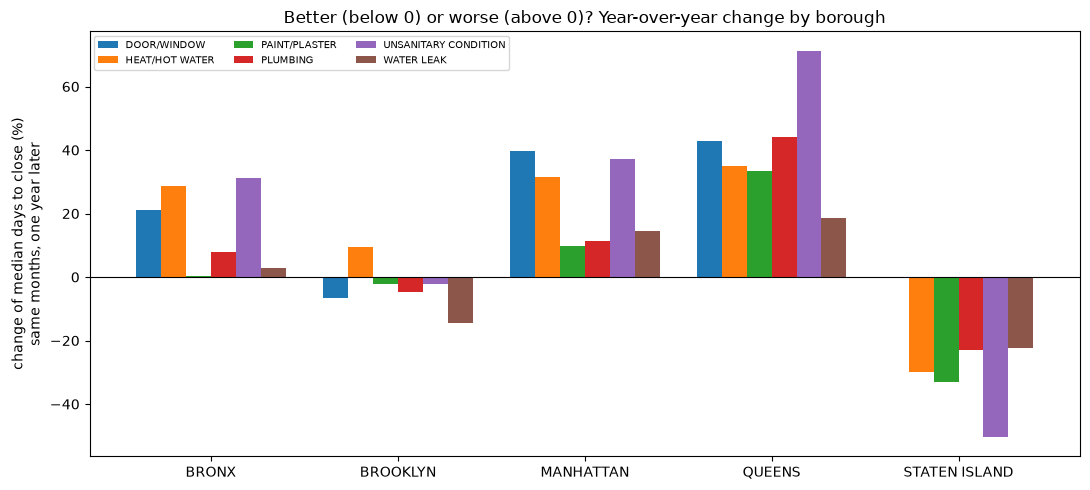

In [19]:
yoy = analysis.year_over_year(borough_median)
analysis.plot_year_over_year(yoy);
yoy.sort_values("change_pct")

کوئینز و منهتن در **همهٔ** نوع‌ها بدتر شده‌اند: میانهٔ زمان بستن در همان ماه‌های سال بعد بیشتر است، در کوئینز تا ۷۱٪ (UNSANITARY CONDITION) و در منهتن تا ۴۰٪ (DOOR/WINDOW). برانکس در بیشتر نوع‌ها کمی بدتر شده. استیتن آیلند در پنج نوع از شش نوع **بهتر** شده (تا ۵۰٪ سریع‌تر)، و بروکلین تقریباً ثابت مانده یا کمی بهتر شده. پس یک عدد برای کل شهر، این تفاوت را پنهان می‌کرد. این مقایسه فقط شش ماه را می‌سنجد، و استیتن آیلند پرونده‌های کمتری دارد و نوسانش بیشتر است.

### ۱۳.۶ نمودار ۴: تمرکز شکایت‌ها روی چند ساختمان

**ادعا:** شکایت‌ها بین آدرس‌ها یکنواخت پخش نشده‌اند. بخش کوچکی از ساختمان‌ها، سهم بزرگی از شکایت‌ها را دارند.

{'addresses': 66878, 'problems': 891788, 'top_address': '31-35 CRESCENT STREET', 'top_address_problems': 4145, 'top_1pct_addresses': 669, 'top_1pct_share_pct': 21.3, 'addresses_for_half_of_problems_pct': 5.7}


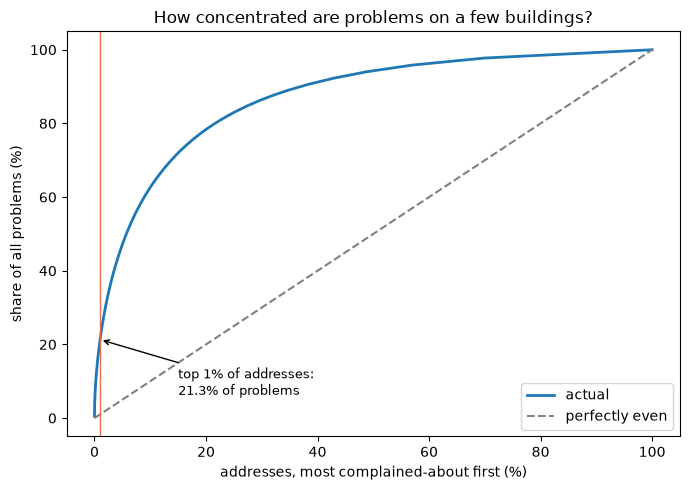

In [20]:
curve, facts = analysis.concentration(cases)
print(facts)
analysis.plot_concentration(curve, facts);

منحنی خیلی بالاتر از خط «پخش یکنواخت» است. **۱٪ آدرس‌ها (۶۶۹ آدرس) ۲۱٫۳٪ کل مشکل‌ها را دارند**، و **نیمی از همهٔ مشکل‌ها فقط از ۵٫۷٪ آدرس‌ها** می‌آید. پرشکایت‌ترین آدرس به‌تنهایی ۴٬۱۴۵ مشکل دارد. یعنی بخشی از «سرعت بستن پرونده» در هر محله، به چند ساختمان بزرگ و پرمشکل بستگی دارد، و هر تحلیل روند در سطح محله باید اثر این ساختمان‌ها را جدا ببیند.

### ۱۳.۷ مقایسهٔ متغیرهای دسته‌ای: borough، نوع شکایت و کانال ثبت

**ادعا:** ترتیب نوع‌ها از نظر سرعت، در همهٔ boroughها تقریباً یکی است، ولی سطح کلی boroughها با هم فرق دارد.

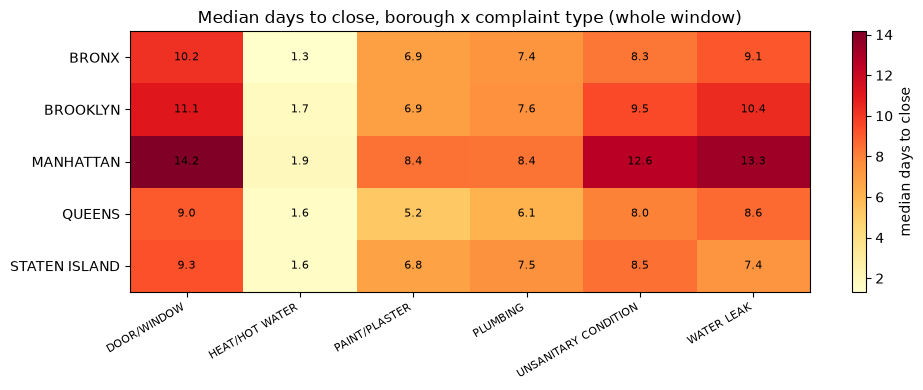

In [21]:
analysis.plot_borough_type_heatmap(analysis.median_by_borough_and_type(cases));

In [22]:
analysis.channel_comparison(cases)

open_data_channel_type,MOBILE,ONLINE,PHONE
complaint_type,,,
DOOR/WINDOW,NaN,11.14,11.09
HEAT/HOT WATER,1.43,1.60,1.69
PAINT/PLASTER,NaN,6.96,7.07
PLUMBING,NaN,6.58,8.07
UNSANITARY CONDITION,NaN,10.75,8.80
WATER LEAK,NaN,11.45,9.40


در همهٔ boroughها، HEAT/HOT WATER سریع‌ترین نوع است و بقیه چندین برابر کندترند. ولی سطح کلی بین boroughها فرق دارد، و منهتن در بیشتر نوع‌ها از کندترین‌هاست.

در جدول کانال ثبت، خانه‌های MOBILE برای همهٔ نوع‌ها جز گرمایش خالی است: در این داده، شکایت با موبایل فقط برای گرمایش ثبت شده. بین ONLINE و PHONE، فاصله در هر نوع حداکثر حدود دو روز است (مثلاً PLUMBING: ۶٫۵۸ در برابر ۸٫۰۷)، و جهتش هم یکسان نیست. این تفاوت از تفاوت بین نوع‌ها (۱٫۶ روز در برابر ۷ تا ۱۱ روز) خیلی کوچک‌تر است.

## ۱۴. سه یافتهٔ غیربدیهی

چیزهایی که قبل از نگاه کردن به داده نمی‌دانستم:

1. **فصل گرما بقیهٔ شکایت‌ها را کند می‌کند.** شکایت گرمایش خودش همیشه حدود یک و نیم روز بسته می‌شود، ولی در ماه‌هایی که تعدادش زیاد است، بقیهٔ نوع‌ها کندتر بسته می‌شوند: همبستگی ۰٫۸۹ در ۱۸ ماه (نمودار ۲). پس روند «بهتر یا بدتر» را فقط با مقایسهٔ **همان ماه در دو سال** می‌شود سنجید، نه دو ماه پشت سر هم.
2. **جواب «بهتر شده یا بدتر؟» به borough بستگی دارد.** در همان ماه‌های سال بعد، کوئینز و منهتن در همهٔ نوع‌ها کندتر شده‌اند و استیتن آیلند در پنج نوع از شش نوع سریع‌تر (نمودار ۳). یک عدد برای کل شهر این را پنهان می‌کرد.
3. **ستون borough دادهٔ ۳۱۱ از نگاشت کد پستی دقیق‌تر است.** قاعدهٔ ساده‌ای که اول به ذهن می‌رسد (borough با بیشترین مساحت) ۲٬۰۰۵ اختلاف کاذب نشان داد، که همه روی کدهای پستی دوتکه بودند. مثلاً Marble Hill، که از نظر قانونی منهتن است ولی به برانکس چسبیده (بخش ۹). با قاعدهٔ درست، اختلاف صفر شد.

یافته‌های دیگر: نیمی از مشکل‌ها فقط از ۵٫۷٪ آدرس‌ها می‌آید (نمودار ۴)؛ کد پستی 11249 در جدول مرجع جمعیت نبود، چون جدول قدیمی‌تر از خود کد پستی است؛ و API فیلدهای خالی را اصلاً نمی‌فرستد، پس فهرست ستون‌ها را فقط از metadata می‌شود گرفت.

محدودیت‌ها و ریسک‌ها در `report.md` آمده‌اند.